## 1. Connect Google Drive and Install Libraries
Google Drive is mounted to access the dataset and the stress-test images. The `transformers` library is installed to load the DINOv2 model.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install transformers
print("Setup complete")

Mounted at /content/drive
Setup complete


## 2. Data Paths and Folder Structure Check
Paths to the original dataset and the stress-test folder are defined. The class names and the number of stress-test images in each condition are verified.

In [3]:
import os, random, numpy as np, pandas as pd, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ROOT = "/content/drive/MyDrive/Computer_Vision_Assignment"
DATA = f"{ROOT}/hand_gesture_dataset"
ST = f"{ROOT}/stress_test"
exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

class_names = sorted([f for f in os.listdir(DATA) if os.path.isdir(f"{DATA}/{f}")])
print("Classes:", class_names)

print("stress_test found:", os.path.exists(ST))
if os.path.exists(ST):
    for cond in sorted(os.listdir(ST)):
        cp = f"{ST}/{cond}"
        if os.path.isdir(cp):
            counts = {c: len([f for f in os.listdir(f"{cp}/{c}") if f.lower().endswith(exts + ('.heic',))])
                      for c in sorted(os.listdir(cp)) if os.path.isdir(f"{cp}/{c}")}
            print(cond, counts)

Classes: ['peace', 'stop', 'thumbs_up']
stress_test found: True
backlight {'peace': 7, 'stop': 9, 'thumbs_up': 7}
blur {'peace': 8, 'stop': 7, 'thumbs_up': 10}
dark {'peace': 7, 'stop': 9, 'thumbs_up': 6}
new_bg {'peace': 9, 'stop': 8, 'thumbs_up': 9}


## 3. Train / Validation / Test Split
The same stratified 70% / 15% / 15% split and the same random seed as in Assignment 1 are used, so the comparison with the A1 baseline is fair.

In [4]:
from sklearn.model_selection import train_test_split

paths, labels = [], []
for c in class_names:
    for f in os.listdir(f"{DATA}/{c}"):
        if f.lower().endswith(exts):
            paths.append(f"{DATA}/{c}/{f}")
            labels.append(c)

df = pd.DataFrame({"filepath": paths, "label": labels})

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1765, stratify=train_val_df["label"], random_state=SEED)

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df), "(A1: 260 / 56 / 56)")

for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(f"{ROOT}/split_{n}.csv", index=False)

Train / Val / Test: 260 56 56 (A1: 260 / 56 / 56)


## 4. Load the SOTA Model: DINOv2
DINOv2 (Meta AI) is a Vision Transformer pretrained with self-supervised learning on a large image collection. The small version is used here as a frozen feature extractor.

In [5]:
from PIL import Image
from transformers import AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

dino = AutoModel.from_pretrained("facebook/dinov2-small").to(device).eval()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def prep(path):
    img = Image.open(path).convert("RGB").resize((224, 224))
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
    return (x - mean) / std

print("DINOv2 loaded successfully")

Device: cuda


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2 loaded successfully


## 5. Feature Extraction
Each image is passed through DINOv2 to obtain a feature vector (CLS token concatenated with the mean of the patch tokens). These vectors are then used to train a lightweight classifier.

In [6]:
@torch.no_grad()
def extract(df_, bs=32):
    feats = []
    for i in range(0, len(df_), bs):
        batch = torch.stack([prep(p) for p in df_["filepath"].values[i:i+bs]]).to(device)
        h = dino(pixel_values=batch).last_hidden_state
        feats.append(torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).cpu().numpy())
    return np.concatenate(feats)

idx = {c: i for i, c in enumerate(class_names)}

Xtr, Xva, Xte = extract(train_df), extract(val_df), extract(test_df)
ytr, yva, yte = [d["label"].map(idx).values for d in (train_df, val_df, test_df)]

print("Feature shapes:", Xtr.shape, Xva.shape, Xte.shape)

Feature shapes: (260, 768) (56, 768) (56, 768)


## 6. Classifier Training and Evaluation
A logistic regression classifier is trained on the DINOv2 features. Accuracy and macro F1-score are computed on the validation and test sets and compared with the A1 baseline CNN (83.93% accuracy) and the fine-tuned MobileNetV2 (80.36% accuracy).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

clf = LogisticRegression(max_iter=3000, C=1.0).fit(Xtr, ytr)

for name, X, y in [("Validation", Xva, yva), ("Test", Xte, yte)]:
    p = clf.predict(X)
    print(f"{name}: accuracy={accuracy_score(y, p):.4f}  macro-F1={f1_score(y, p, average='macro'):.4f}")

print()
print(classification_report(yte, clf.predict(Xte), target_names=class_names))

Validation: accuracy=1.0000  macro-F1=1.0000
Test: accuracy=1.0000  macro-F1=1.0000

              precision    recall  f1-score   support

       peace       1.00      1.00      1.00        19
        stop       1.00      1.00      1.00        18
   thumbs_up       1.00      1.00      1.00        19

    accuracy                           1.00        56
   macro avg       1.00      1.00      1.00        56
weighted avg       1.00      1.00      1.00        56



## 7. Stress-Test Evaluation of DINOv2
The stress-test images (dark, backlight, new background, motion blur) were never used for training. They are used to measure how robust the DINOv2 classifier is under difficult conditions.

In [8]:
!pip -q install pillow-heif
import pillow_heif
pillow_heif.register_heif_opener()

all_ext = exts + ('.heic', '.heif')
rows = []
for cond in sorted(os.listdir(ST)):
    for c in class_names:
        folder = f"{ST}/{cond}/{c}"
        if os.path.isdir(folder):
            for f in sorted(os.listdir(folder)):
                if f.lower().endswith(all_ext):
                    rows.append({"filepath": f"{folder}/{f}", "condition": cond, "label": c})

stress_df = pd.DataFrame(rows)
print(stress_df.groupby("condition").size())
print("Total stress images:", len(stress_df))

Xst = extract(stress_df)
stress_df["dino_pred"] = clf.predict(Xst)
stress_df["y"] = stress_df["label"].map(idx)

for cond, g in stress_df.groupby("condition"):
    print(f"{cond}: DINOv2 accuracy = {accuracy_score(g['y'], g['dino_pred']):.3f}")
print(f"Overall: {accuracy_score(stress_df['y'], stress_df['dino_pred']):.3f}")

condition
backlight    23
blur         25
dark         22
new_bg       26
dtype: int64
Total stress images: 96
backlight: DINOv2 accuracy = 0.391
blur: DINOv2 accuracy = 0.360
dark: DINOv2 accuracy = 0.409
new_bg: DINOv2 accuracy = 0.538
Overall: 0.427


## 8. Stress-Test Evaluation of the A1 Baseline CNN
The saved baseline CNN from Assignment 1 is evaluated on the same stress-test images, using the same resizing as in A1. Both models are then compared per condition.

,backlight,blur,dark,new_bg,overall
A1 Baseline CNN,39.1,28.0,27.3,46.2,35.4
DINOv2 + LogReg,39.1,36.0,40.9,53.8,42.7


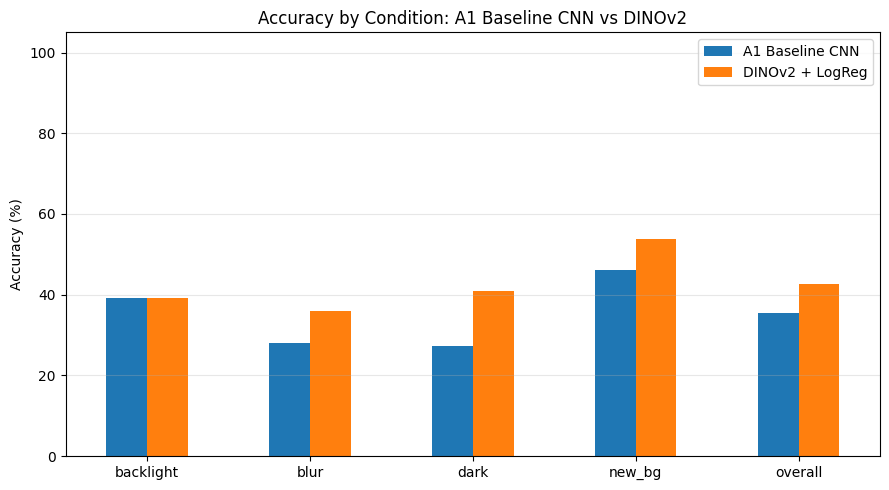

In [9]:
import tensorflow as tf

cnn = tf.keras.models.load_model(f"{ROOT}/best_hand_gesture_cnn.keras")

def load_for_cnn(path):
    arr = np.array(Image.open(path).convert("RGB"))
    return tf.image.resize(arr, (224, 224)).numpy()

Xcnn = np.stack([load_for_cnn(p) for p in stress_df["filepath"]])
stress_df["cnn_pred"] = np.argmax(cnn.predict(Xcnn, batch_size=16, verbose=0), axis=1)

def summarize(col):
    out = {cond: accuracy_score(g["y"], g[col]) for cond, g in stress_df.groupby("condition")}
    out["overall"] = accuracy_score(stress_df["y"], stress_df[col])
    return out

comp = pd.DataFrame({
    "A1 Baseline CNN": summarize("cnn_pred"),
    "DINOv2 + LogReg": summarize("dino_pred")
}).T
comp = (comp * 100).round(1)
display(comp)
comp.to_csv(f"{ROOT}/stress_results.csv")

import matplotlib.pyplot as plt
comp.T.plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy by Condition: A1 Baseline CNN vs DINOv2")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{ROOT}/stress_comparison.png", dpi=200)
plt.show()

## 9. Inference Latency
Average per-image inference time (preprocessing excluded from the model-only comparison, included in the full pipeline) is measured for both models on the same device.

In [10]:
import time

sample = stress_df["filepath"].iloc[0]
cnn_in = load_for_cnn(sample)[None]

def dino_pipeline():
    x = prep(sample).unsqueeze(0).to(device)
    with torch.no_grad():
        h = dino(pixel_values=x).last_hidden_state
    f = torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).cpu().numpy()
    return clf.predict(f)

def cnn_pipeline():
    return cnn(cnn_in, training=False).numpy()

def avg_ms(fn, n=30):
    fn()  # warm-up
    t = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t) / n * 1000

print(f"Device: {device}")
print(f"A1 Baseline CNN : {avg_ms(cnn_pipeline):.1f} ms/image")
print(f"DINOv2 + LogReg : {avg_ms(dino_pipeline):.1f} ms/image (incl. preprocessing)")

Device: cuda
A1 Baseline CNN : 14.7 ms/image
DINOv2 + LogReg : 49.8 ms/image (incl. preprocessing)


## 10. Error Analysis on the Stress Test
The confusion matrix and the predicted class distribution show how DINOv2 fails under difficult conditions. Image orientation and size statistics of the original training images and the stress-test images are compared to detect possible domain mismatch. Several misclassified images are displayed.

DINOv2 stress-test confusion matrix (rows = true, columns = predicted):
           peace  stop  thumbs_up
peace          4    22          5
stop           6    26          1
thumbs_up      0    21         11

Predicted class counts: {'stop': 69, 'thumbs_up': 17, 'peace': 10}

Original train (60 sampled): n=60, portrait=55, landscape=5, EXIF orientation != 1: 0
Stress test (all): n=96, portrait=96, landscape=0, EXIF orientation != 1: 0


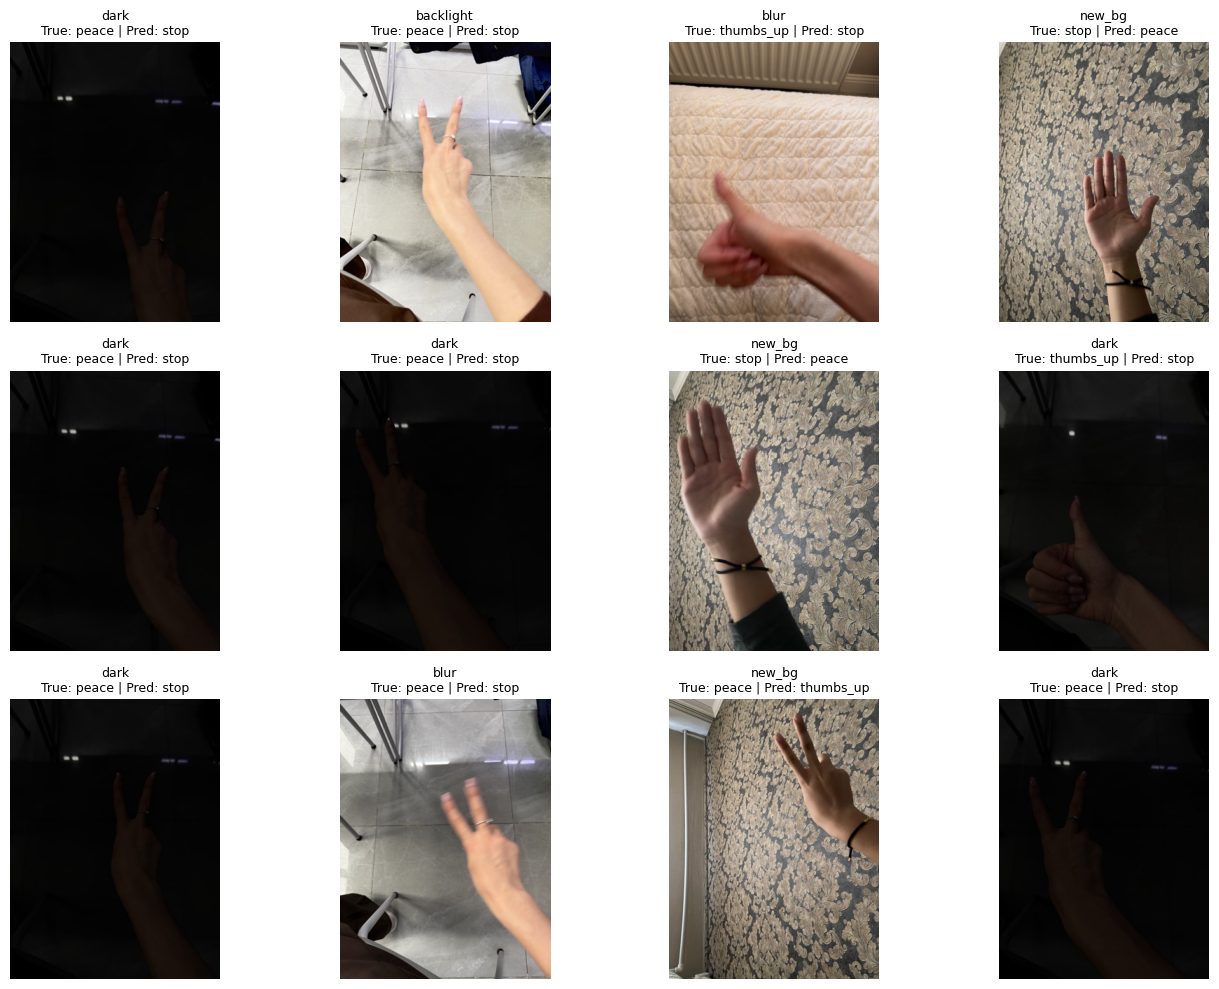

In [11]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# (a) Confusion matrix on stress images
cm = confusion_matrix(stress_df["y"], stress_df["dino_pred"])
print("DINOv2 stress-test confusion matrix (rows = true, columns = predicted):")
print(pd.DataFrame(cm, index=class_names, columns=class_names))
print("\nPredicted class counts:",
      stress_df["dino_pred"].map(lambda i: class_names[i]).value_counts().to_dict())

# (b) Orientation / size statistics
def info(path):
    img = Image.open(path)
    try:
        orient = img.getexif().get(274, 1)
    except Exception:
        orient = 1
    return img.size, orient

def orient_summary(paths, name):
    sizes, orients = zip(*[info(p) for p in paths])
    portrait = sum(h > w for w, h in sizes)
    print(f"{name}: n={len(paths)}, portrait={portrait}, landscape={len(paths)-portrait}, "
          f"EXIF orientation != 1: {sum(o != 1 for o in orients)}")

print()
orient_summary(train_df["filepath"].sample(60, random_state=0).tolist(), "Original train (60 sampled)")
orient_summary(stress_df["filepath"].tolist(), "Stress test (all)")

# (c) Misclassified examples
wrong = stress_df[stress_df["y"] != stress_df["dino_pred"]].sample(12, random_state=1)
plt.figure(figsize=(14, 10))
for i, (_, r) in enumerate(wrong.iterrows()):
    im = Image.open(r["filepath"]).convert("RGB")
    im.thumbnail((400, 400))
    plt.subplot(3, 4, i + 1)
    plt.imshow(im)
    plt.title(f"{r['condition']}\nTrue: {r['label']} | Pred: {class_names[r['dino_pred']]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Synthetic Condition Augmentation and Ablation
Synthetic difficult conditions (low light, overexposure, motion blur, noise, random crops) are generated programmatically from the training images only. DINOv2 features are extracted from these synthetic images and the classifier is retrained. The result is compared with the classifier trained on real images only (ablation). The stress-test images are never used for training. All synthetic images are generated offline and are clearly marked as synthetic.

  0%|          | 0/260 [00:00<?, ?it/s]

Synthetic images: 1040 | synthetic share of training set: 80%

Original test accuracy:
  DINOv2 (real only):        1.0000
  DINOv2 (real + synthetic): 1.0000


,backlight,blur,dark,new_bg,overall
A1 Baseline CNN,39.1,28.0,27.3,46.2,35.4
DINOv2 (real only),39.1,36.0,40.9,53.8,42.7
DINOv2 + synthetic aug.,39.1,36.0,54.5,65.4,49.0


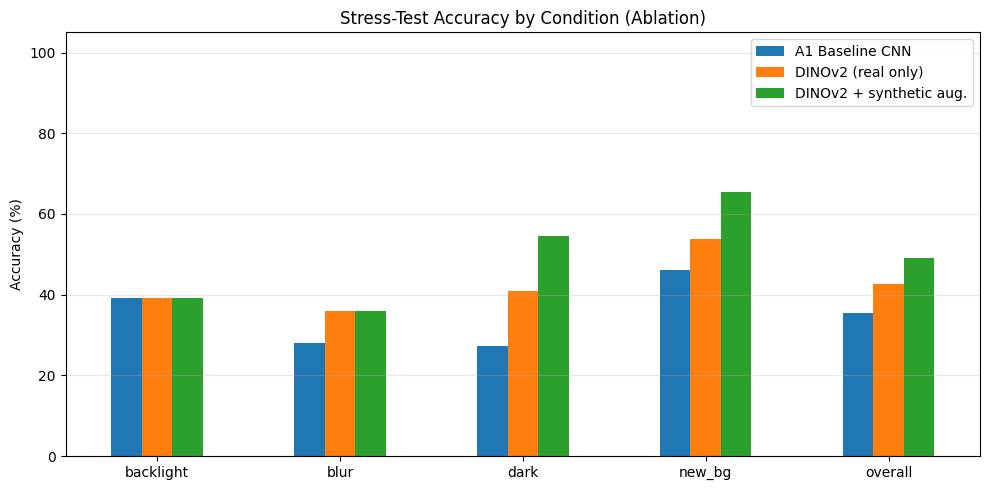

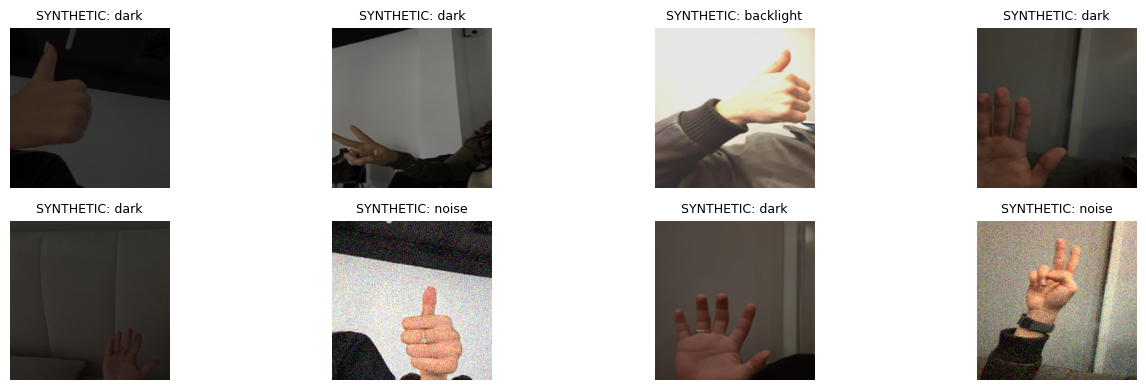

In [12]:
from PIL import ImageEnhance, ImageOps
from tqdm.auto import tqdm

rng = np.random.default_rng(SEED)

def motion_blur(img, k):
    arr = np.asarray(img).astype(np.float32)
    axis = int(rng.integers(0, 2))
    acc = sum(np.roll(arr, s - k // 2, axis=axis) for s in range(k)) / k
    return Image.fromarray(acc.clip(0, 255).astype(np.uint8))

def add_noise(img, sigma):
    arr = np.asarray(img).astype(np.float32)
    arr = arr + rng.normal(0, sigma, arr.shape)
    return Image.fromarray(arr.clip(0, 255).astype(np.uint8))

def random_crop(img, scale=(0.55, 1.0)):
    w, h = img.size
    s = rng.uniform(*scale)
    cw, ch = int(w * np.sqrt(s)), int(h * np.sqrt(s))
    x0 = int(rng.integers(0, w - cw + 1)); y0 = int(rng.integers(0, h - ch + 1))
    return img.crop((x0, y0, x0 + cw, y0 + ch)).resize((224, 224))

def synthesize(img):
    img = random_crop(img)
    if rng.random() < 0.5:
        img = ImageOps.mirror(img)
    cond = str(rng.choice(["dark", "backlight", "blur", "noise"]))
    if cond == "dark":
        img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.2, 0.6))
    elif cond == "backlight":
        img = ImageEnhance.Brightness(img).enhance(rng.uniform(1.4, 2.0))
        img = ImageEnhance.Contrast(img).enhance(rng.uniform(0.5, 0.9))
    elif cond == "blur":
        img = motion_blur(img, int(rng.integers(5, 15)))
    else:
        img = add_noise(img, rng.uniform(10, 35))
    return img, cond

def prep_pil(img):
    x = torch.from_numpy(np.array(img.convert("RGB").resize((224, 224)))).permute(2, 0, 1).float() / 255.0
    return (x - mean) / std

@torch.no_grad()
def feats_from_pils(imgs, bs=32):
    out = []
    for i in range(0, len(imgs), bs):
        batch = torch.stack([prep_pil(im) for im in imgs[i:i+bs]]).to(device)
        h = dino(pixel_values=batch).last_hidden_state
        out.append(torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).cpu().numpy())
    return np.concatenate(out)

# Generate synthetic images from TRAIN images only
N_SYNTH = 4
syn_imgs, syn_y, syn_cond = [], [], []
for path, lab in tqdm(zip(train_df["filepath"], train_df["label"]), total=len(train_df)):
    im = Image.open(path)
    im.draft("RGB", (448, 448))
    im = im.convert("RGB").resize((224, 224))
    for _ in range(N_SYNTH):
        s, c = synthesize(im)
        syn_imgs.append(s); syn_y.append(idx[lab]); syn_cond.append(c)

Xsyn, ysyn = feats_from_pils(syn_imgs), np.array(syn_y)
share = 100 * len(ysyn) / (len(ysyn) + len(ytr))
print(f"Synthetic images: {len(ysyn)} | synthetic share of training set: {share:.0f}%")

# Retrain classifier on real + synthetic features
clf_syn = LogisticRegression(max_iter=3000, C=1.0).fit(
    np.vstack([Xtr, Xsyn]), np.concatenate([ytr, ysyn]))

stress_df["dino_syn_pred"] = clf_syn.predict(Xst)

print("\nOriginal test accuracy:")
print(f"  DINOv2 (real only):        {accuracy_score(yte, clf.predict(Xte)):.4f}")
print(f"  DINOv2 (real + synthetic): {accuracy_score(yte, clf_syn.predict(Xte)):.4f}")

comp = pd.DataFrame({
    "A1 Baseline CNN": summarize("cnn_pred"),
    "DINOv2 (real only)": summarize("dino_pred"),
    "DINOv2 + synthetic aug.": summarize("dino_syn_pred"),
}).T
comp = (comp * 100).round(1)
display(comp)
comp.to_csv(f"{ROOT}/stress_results_ablation.csv")

comp.T.plot(kind="bar", figsize=(10, 5))
plt.title("Stress-Test Accuracy by Condition (Ablation)")
plt.ylabel("Accuracy (%)"); plt.xticks(rotation=0); plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3); plt.tight_layout()
plt.savefig(f"{ROOT}/stress_ablation.png", dpi=200)
plt.show()

# Examples of synthetic images (for the report)
plt.figure(figsize=(14, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(syn_imgs[i * 13])
    plt.title(f"SYNTHETIC: {syn_cond[i * 13]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig(f"{ROOT}/synthetic_examples.png", dpi=200)
plt.show()

## 12. Explainability: Attention Rollout
Attention rollout multiplies the self-attention matrices of all transformer layers to show which image regions the DINOv2 model uses for its prediction. Red areas indicate high attention. The first row shows images from the original test set, the other rows show stress-test images with the predictions of the final model (trained with synthetic augmentation).

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

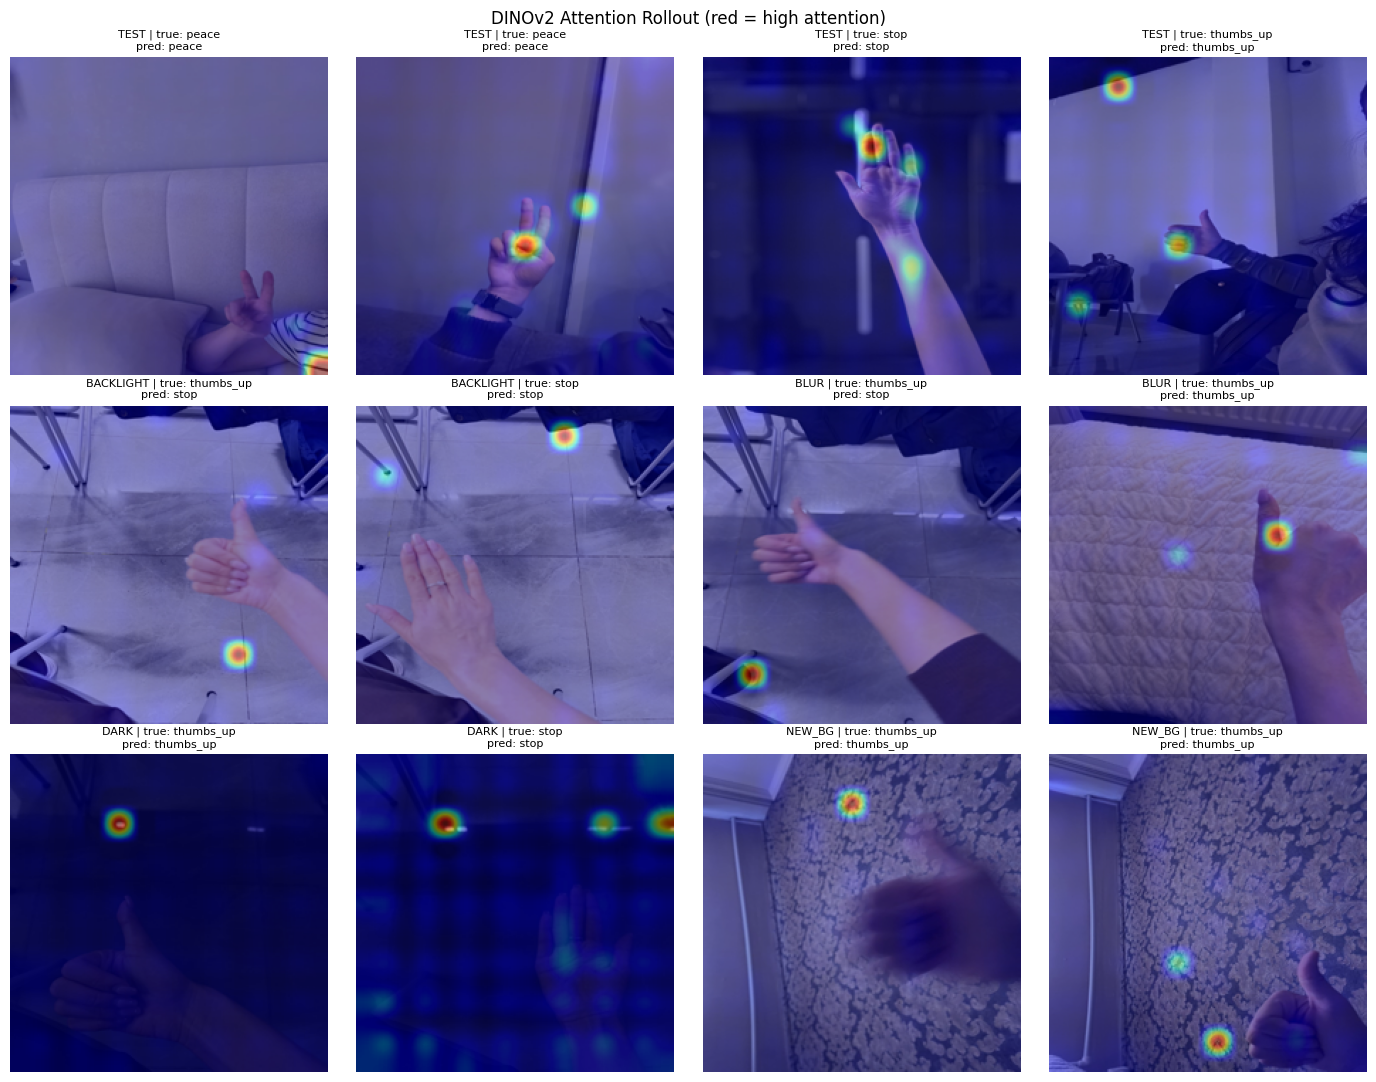

In [13]:
# Attention maps require the "eager" attention implementation
dino_attn = AutoModel.from_pretrained(
    "facebook/dinov2-small", attn_implementation="eager"
).to(device).eval()

@torch.no_grad()
def attention_rollout(path):
    x = prep(path).unsqueeze(0).to(device)
    attentions = dino_attn(pixel_values=x, output_attentions=True).attentions
    T = attentions[0].shape[-1]
    result = torch.eye(T, device=device)
    for a in attentions:
        a = a.mean(dim=1)[0]                  # average over heads -> (T, T)
        a = a + torch.eye(T, device=device)   # residual connection
        a = a / a.sum(dim=-1, keepdim=True)
        result = a @ result
    mask = result[0, 1:]                      # CLS token -> image patches
    n = int(mask.numel() ** 0.5)
    mask = mask.reshape(n, n).cpu().numpy()
    return (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)

def show_overlay(ax, path, title):
    img = Image.open(path)
    img.draft("RGB", (448, 448))
    img = img.convert("RGB").resize((224, 224))
    m = Image.fromarray((attention_rollout(path) * 255).astype(np.uint8)).resize((224, 224), Image.BICUBIC)
    ax.imshow(img)
    ax.imshow(np.array(m), cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=8)
    ax.axis("off")

test_sel = test_df.sample(4, random_state=3)
test_pred = dict(zip(test_df["filepath"], clf_syn.predict(Xte)))
stress_sel = pd.concat([g.sample(2, random_state=3) for _, g in stress_df.groupby("condition")])

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
axes = axes.ravel()
for ax, (_, r) in zip(axes[:4], test_sel.iterrows()):
    show_overlay(ax, r["filepath"], f"TEST | true: {r['label']}\npred: {class_names[test_pred[r['filepath']]]}")
for ax, (_, r) in zip(axes[4:], stress_sel.iterrows()):
    show_overlay(ax, r["filepath"], f"{r['condition'].upper()} | true: {r['label']}\npred: {class_names[r['dino_syn_pred']]}")
plt.suptitle("DINOv2 Attention Rollout (red = high attention)")
plt.tight_layout()
plt.savefig(f"{ROOT}/attention_rollout.png", dpi=200)
plt.show()

## 13. Save Models and Results to Google Drive
The trained classifiers, class names, and stress-test predictions are saved to Google Drive so that the demo application can be built and run later without retraining.

In [14]:
import joblib, json

joblib.dump(clf_syn, f"{ROOT}/dinov2_logreg_synth.joblib")
joblib.dump(clf, f"{ROOT}/dinov2_logreg_real_only.joblib")
json.dump(class_names, open(f"{ROOT}/class_names.json", "w"))
stress_df.to_csv(f"{ROOT}/stress_predictions.csv", index=False)

print("Saved files:", sorted(f for f in os.listdir(ROOT) if f.endswith((".joblib", ".json", ".csv", ".png"))))

Saved files: ['attention_rollout.png', 'class_names.json', 'dinov2_logreg_real_only.joblib', 'dinov2_logreg_synth.joblib', 'split_test.csv', 'split_train.csv', 'split_val.csv', 'stress_ablation.png', 'stress_comparison.png', 'stress_predictions.csv', 'stress_results.csv', 'stress_results_ablation.csv', 'synthetic_examples.png']


## 14. Explainability: Occlusion Sensitivity
Attention rollout on DINOv2 highlights small isolated regions that are often not on the hand (a known artifact of Vision Transformers without register tokens), so it is not a reliable explanation here. As a more faithful alternative, occlusion sensitivity is used: a gray square is slid over the image, and the drop in the predicted-class probability is measured. Red areas are regions the prediction depends on. The final classifier (trained with synthetic augmentation) is used.

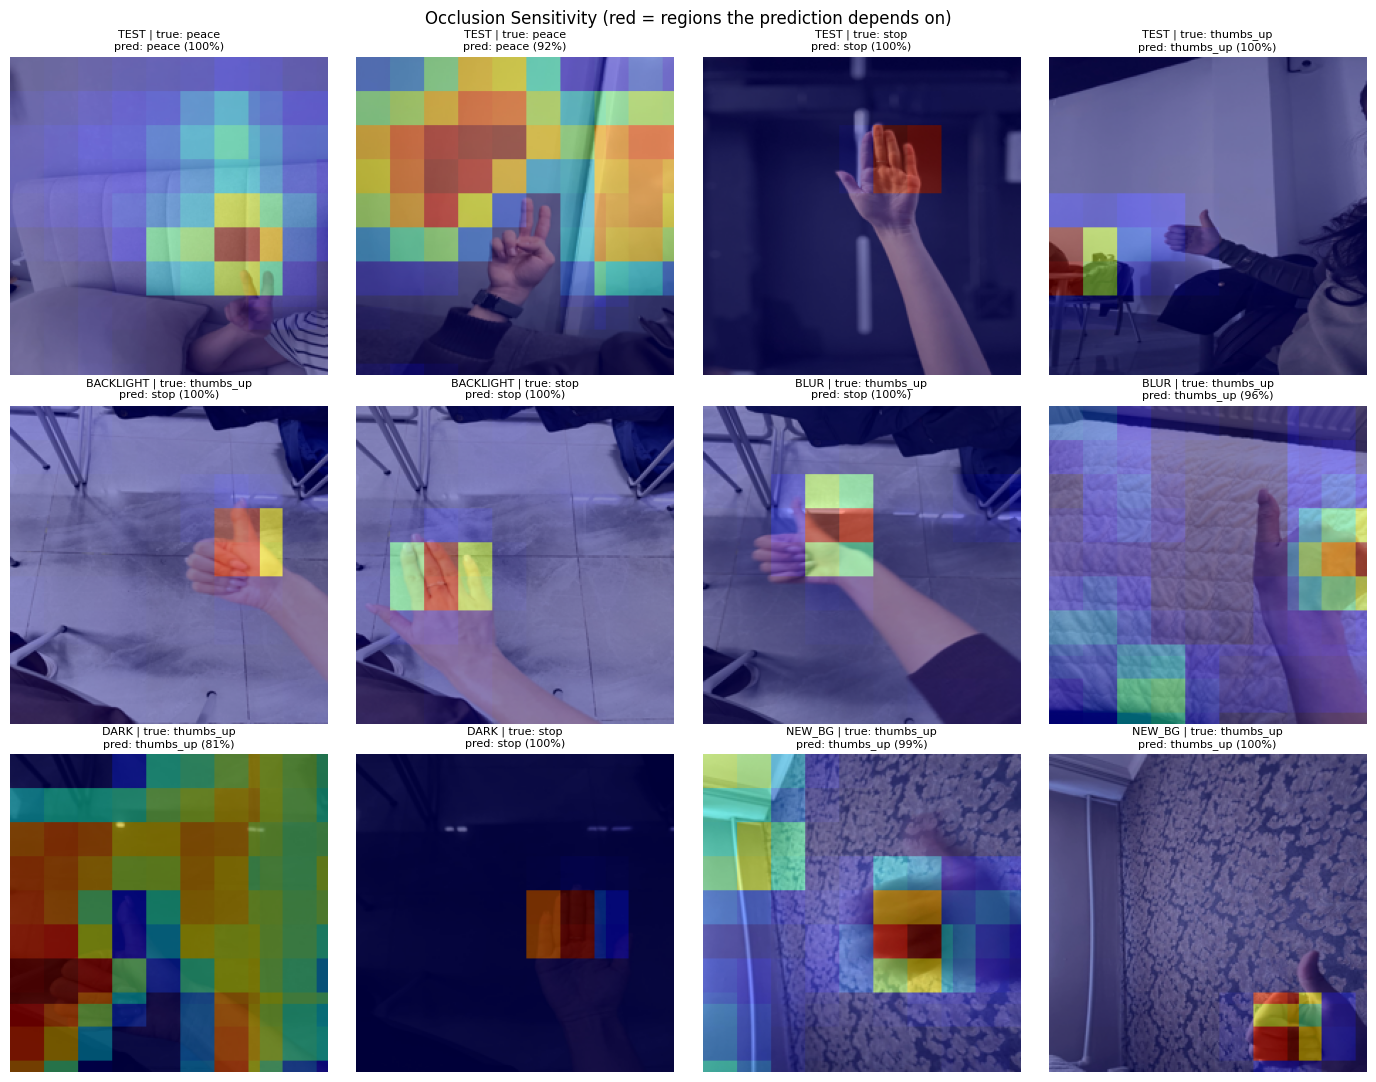

In [15]:
def predict_proba_pil(imgs):
    return clf_syn.predict_proba(feats_from_pils(imgs))

def load_small(path):
    img = Image.open(path)
    img.draft("RGB", (448, 448))
    return img.convert("RGB").resize((224, 224))

def occlusion_map(pil_img, patch=48, stride=24):
    img = pil_img.convert("RGB").resize((224, 224))
    base = predict_proba_pil([img])[0]
    cls = int(base.argmax())

    positions = list(range(0, 224 - patch + 1, stride))
    if positions[-1] != 224 - patch:
        positions.append(224 - patch)

    gray = Image.new("RGB", (patch, patch), (124, 116, 104))
    occluded, coords = [], []
    for y in positions:
        for x in positions:
            im = img.copy()
            im.paste(gray, (x, y))
            occluded.append(im)
            coords.append((x, y))

    probs = predict_proba_pil(occluded)[:, cls]
    drops = base[cls] - probs

    heat = np.zeros((224, 224)); count = np.zeros((224, 224))
    for (x, y), d in zip(coords, drops):
        heat[y:y + patch, x:x + patch] += d
        count[y:y + patch, x:x + patch] += 1
    heat = np.clip(heat / count, 0, None)
    heat = heat / (heat.max() + 1e-8)
    return img, heat, cls, base

items = (
    [(r["filepath"], f"TEST | true: {r['label']}") for _, r in test_sel.iterrows()] +
    [(r["filepath"], f"{r['condition'].upper()} | true: {r['label']}") for _, r in stress_sel.iterrows()]
)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, (path, title) in zip(axes.ravel(), items):
    img, heat, cls, proba = occlusion_map(load_small(path))
    ax.imshow(img)
    ax.imshow(heat, cmap="jet", alpha=0.45)
    ax.set_title(f"{title}\npred: {class_names[cls]} ({proba[cls]*100:.0f}%)", fontsize=8)
    ax.axis("off")
plt.suptitle("Occlusion Sensitivity (red = regions the prediction depends on)")
plt.tight_layout()
plt.savefig(f"{ROOT}/occlusion_maps.png", dpi=200)
plt.show()

## 15. Interactive Demo App (Gradio)
The app accepts an uploaded image or a webcam photo, optionally applies a synthetic stress condition (stress-test generator), predicts the gesture with DINOv2 + logistic regression, shows the occlusion-sensitivity explanation, and reports the inference time and the device. Modified images are clearly labeled as SYNTHETIC.

In [16]:
!pip -q install gradio
import gradio as gr, time
import matplotlib.cm as cm

def apply_condition(img, cond, s):
    img = img.convert("RGB").resize((224, 224))
    if cond == "Dark":
        return ImageEnhance.Brightness(img).enhance(1 - 0.8 * s)
    if cond == "Backlight":
        img = ImageEnhance.Brightness(img).enhance(1 + 1.0 * s)
        return ImageEnhance.Contrast(img).enhance(1 - 0.5 * s)
    if cond == "Motion blur":
        return motion_blur(img, int(3 + 20 * s))
    if cond == "Noise":
        return add_noise(img, 50 * s)
    return img

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

def predict(img, cond, strength):
    if img is None:
        return None, None, None, "Please upload an image or take a webcam photo."
    mod = apply_condition(img, cond, strength)

    t0 = time.perf_counter()
    proba = predict_proba_pil([mod])[0]
    ms = (time.perf_counter() - t0) * 1000
    cls = int(proba.argmax())

    _, heat, _, _ = occlusion_map(mod)
    colored = Image.fromarray((cm.jet(heat)[..., :3] * 255).astype(np.uint8))
    overlay = Image.blend(mod, colored, 0.45)

    notes = []
    if cond != "None":
        notes.append(f"SYNTHETIC condition applied: {cond} (strength {strength:.2f})")
    if np.array(mod.convert("L")).mean() < 30:
        notes.append("WARNING: the image is very dark, the gesture may be invisible.")
    if proba.max() < 0.6:
        notes.append("WARNING: low confidence, the prediction may be unreliable.")
    notes.append(f"Prediction: {class_names[cls]} ({proba[cls]*100:.1f}%)")
    notes.append(f"Inference time: {ms:.0f} ms | Device: {GPU_NAME} (Google Colab) | Model: DINOv2-small + LogReg")

    label = {class_names[i]: float(proba[i]) for i in range(len(class_names))}
    return label, mod, overlay, "\n".join(notes)

with gr.Blocks(title="Hand Gesture Recognition (DINOv2)") as demo:
    gr.Markdown(
        "# Hand Gesture Recognition: Peace / Stop / Thumbs Up\n"
        "DINOv2 + logistic regression. Upload an image or use the webcam. "
        "The stress-test generator creates **synthetic** modified images."
    )
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", sources=["upload", "webcam"], label="Input image")
            cond = gr.Dropdown(["None", "Dark", "Backlight", "Motion blur", "Noise"],
                               value="None", label="Stress-test generator (synthetic condition)")
            strength = gr.Slider(0, 1, value=0.5, step=0.05, label="Condition strength")
            btn = gr.Button("Predict", variant="primary")
        with gr.Column():
            out_label = gr.Label(num_top_classes=3, label="Class probabilities")
            out_mod = gr.Image(label="Model input (SYNTHETIC if a condition is applied)")
            out_exp = gr.Image(label="Explanation: occlusion sensitivity (red = important)")
            out_info = gr.Textbox(label="Info", lines=5)
    btn.click(predict, [inp, cond, strength], [out_label, out_mod, out_exp, out_info])

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c59a0fc74151b7615.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 16. Learning Curve and Explanation Latency
Since DINOv2 + logistic regression has no training epochs, a learning curve is used instead: the classifier is trained on increasing fractions of the training features, and accuracy is measured on the validation set and on the stress-test set (used for evaluation only). The latency of the occlusion-based explanation is also measured.

,fraction,n_train,train_acc,val_acc,stress_acc
0,0.1,26,1.0,0.571,0.385
1,0.2,52,1.0,0.732,0.365
2,0.4,104,1.0,0.929,0.375
3,0.6,156,1.0,1.000,0.417
4,0.8,208,1.0,1.000,0.406
5,1.0,260,1.0,1.000,0.427


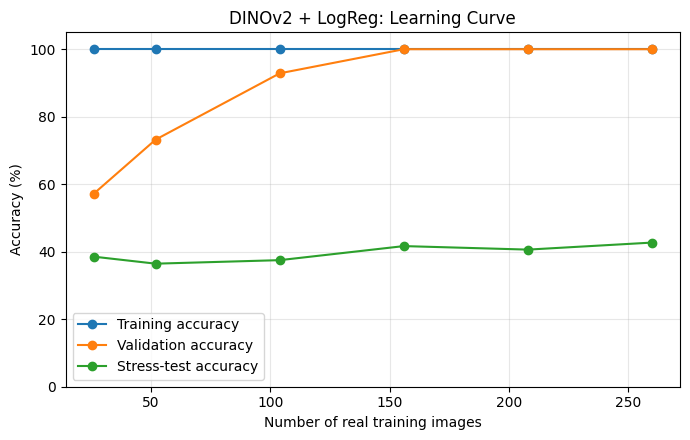

Occlusion explanation time: 689 ms/image


In [17]:
fractions = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
perm = np.random.default_rng(SEED).permutation(len(ytr))

rows = []
for fr in fractions:
    n = int(len(ytr) * fr)
    sel = perm[:n]
    if len(np.unique(ytr[sel])) < len(class_names):
        continue
    m = LogisticRegression(max_iter=3000).fit(Xtr[sel], ytr[sel])
    rows.append({
        "fraction": fr, "n_train": n,
        "train_acc": accuracy_score(ytr[sel], m.predict(Xtr[sel])),
        "val_acc": accuracy_score(yva, m.predict(Xva)),
        "stress_acc": accuracy_score(stress_df["y"], m.predict(Xst)),
    })
lc = pd.DataFrame(rows)
display(lc.round(3))
lc.to_csv(f"{ROOT}/learning_curve.csv", index=False)

plt.figure(figsize=(7, 4.5))
plt.plot(lc["n_train"], lc["train_acc"] * 100, "o-", label="Training accuracy")
plt.plot(lc["n_train"], lc["val_acc"] * 100, "o-", label="Validation accuracy")
plt.plot(lc["n_train"], lc["stress_acc"] * 100, "o-", label="Stress-test accuracy")
plt.xlabel("Number of real training images")
plt.ylabel("Accuracy (%)")
plt.title("DINOv2 + LogReg: Learning Curve")
plt.ylim(0, 105); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(f"{ROOT}/learning_curve.png", dpi=200)
plt.show()

# Latency of the occlusion explanation
sample = stress_df["filepath"].iloc[0]
t0 = time.perf_counter()
_ = occlusion_map(load_small(sample))
print(f"Occlusion explanation time: {(time.perf_counter() - t0) * 1000:.0f} ms/image")